# Práctica de Deep Learning para Finanzas · Avance 1 (capítulo 7)
**Ciencia de Datos Aplicada a la Economía** · Prof. Rubén Miguel Rodríguez Rangel · Luis Enrique López Salazar

Objetivo del avance: preparar datos confiables y establecer referencias que permitan valorar el aporte del modelo profundo.

Entregable (protocolo §4): datos auditados, tabla de particiones, dos modelos de referencia (cero y regresión lineal) y una hipótesis técnica.
En este avance **no se usa TE**: solo se reportan sus fechas y tamaño.

## 1. Configuración, versiones y semilla

In [1]:
# En Colab: !pip install -q pandas numpy matplotlib scikit-learn   (ya vienen instalados)
import hashlib, json, os, platform, sys, time, urllib.error, urllib.request
from datetime import datetime, timezone
import numpy as np, pandas as pd, matplotlib, sklearn
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEMILLA = 42
np.random.seed(SEMILLA)
SIMBOLO, INTERVALO = "BTCUSDT", "1d"
FUENTE = "https://api.mexc.com/api/v3/klines"
VENTANA = 20                      # 20 rendimientos más recientes hasta t (protocolo §3)
PROP = {"TR": 0.70, "VA": 0.15, "TE": 0.15}
for d in ["data/raw", "data/processed", "outputs", "figures"]:
    os.makedirs(d, exist_ok=True)
VERSIONES = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
             "scikit-learn": sklearn.__version__, "matplotlib": matplotlib.__version__}
print(VERSIONES, "| semilla", SEMILLA, "| dispositivo: CPU (modelos clásicos; la T4 empieza en el Avance 2)")

{'python': '3.12.3', 'pandas': '3.1.0', 'numpy': '2.5.4', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'} | semilla 42 | dispositivo: CPU (modelos clásicos; la T4 empieza en el Avance 2)


## 2. Ficha del activo
Elegimos **criptomonedas**: el par **BTC/USDT** en **MEXC** (el protocolo menciona que MEXC tiene opción de 0 comisiones, lo que servirá en la simulación).

In [2]:
FICHA = {
    "mercado": "Criptomonedas", "activo": "Bitcoin (BTC)", "moneda_cotizada": "USDT (Tether, dólar estable)",
    "simbolo": SIMBOLO, "plataforma_origen": "MEXC (API pública /api/v3/klines, sin cuenta)",
    "frecuencia": "1d", "zona_horaria": "UTC (la vela diaria de MEXC abre a las 00:00 UTC desde 2018-08-23)",
    "calendario": "continuo, 7 días a la semana; no hay días sin negociación que rellenar",
    "ajustes": "no aplica (sin dividendos ni particiones); precios tal como los publica MEXC",
    "variables": "apertura, máximo, mínimo, cierre, volumen en BTC y volumen en USDT (todas las da la fuente)",
}   # la fecha de descarga se agrega en la sección 3 (la real, aunque se use la copia local)
pd.Series(FICHA, name="valor").to_frame()

,valor
mercado,Criptomonedas
activo,Bitcoin (BTC)
moneda_cotizada,"USDT (Tether, dólar estable)"
simbolo,BTCUSDT
plataforma_origen,"MEXC (API pública /api/v3/klines, sin cuenta)"
frecuencia,1d
zona_horaria,UTC (la vela diaria de MEXC abre a las 00:00 U...
calendario,"continuo, 7 días a la semana; no hay días sin ..."
ajustes,no aplica (sin dividendos ni particiones); pre...
variables,"apertura, máximo, mínimo, cierre, volumen en B..."


## 3. Descarga con controles
MEXC devuelve como máximo 500 velas por consulta, así que se pide por tramos de 450 días con `startTime` y `endTime`.
Si la descarga falla o llega vacía, el flujo **se detiene** e informa fuente, activo y causa. Solo si existe la copia local
`data/raw/mexc_btcusdt_1d_raw.csv` (con su fecha de descarga guardada) se usa, y se declara.

In [3]:
DIA_MS = 86_400_000
COLS = ["open_time", "open", "high", "low", "close", "volume", "close_time", "quote_volume"]
RAW = f"data/raw/mexc_{SIMBOLO.lower()}_{INTERVALO}_raw.csv"

class DatosVacios(Exception):
    pass

def descargar(inicio_ms=1_500_000_000_000):
    filas, s, fin = [], inicio_ms, int(time.time() * 1000)
    while s < fin:
        url = f"{FUENTE}?symbol={SIMBOLO}&interval={INTERVALO}&startTime={s}&endTime={s + 450 * DIA_MS}"
        with urllib.request.urlopen(url, timeout=30) as r:
            filas += json.load(r)
        s += 450 * DIA_MS
    if not filas:
        raise DatosVacios(f"MEXC devolvió 0 velas para {SIMBOLO} {INTERVALO}. Revisa el símbolo o la conexión.")
    return pd.DataFrame([f[:8] for f in filas], columns=COLS)

try:
    crudo = descargar()
    DESCARGA_MS = int(time.time() * 1000)
    crudo.to_csv(RAW, index=False)
    json.dump({"fuente": FUENTE, "simbolo": SIMBOLO, "descarga_ms": DESCARGA_MS, "filas": len(crudo)}, open(RAW + ".meta.json", "w"), indent=1)
    origen = "API de MEXC (descarga nueva)"
except (urllib.error.URLError, TimeoutError, DatosVacios) as e:
    if not (os.path.exists(RAW) and os.path.exists(RAW + ".meta.json")):
        raise SystemExit(f"Descarga fallida · fuente {FUENTE} · activo {SIMBOLO} · causa: {e}. "
                         f"No hay copia local trazable ({RAW} y su .meta.json): se detiene.")
    meta = json.load(open(RAW + ".meta.json"))
    if meta["simbolo"] != SIMBOLO:
        raise SystemExit(f"La copia local es de {meta['simbolo']}, no de {SIMBOLO}: se detiene.")
    crudo, DESCARGA_MS = pd.read_csv(RAW), meta["descarga_ms"]
    origen = f"copia local {RAW}; causa de no descargar: {e}"
FICHA["fecha_descarga_utc"] = datetime.fromtimestamp(DESCARGA_MS / 1000, timezone.utc).strftime("%Y-%m-%d %H:%M")
HUELLA_RAW = hashlib.sha256(open(RAW, "rb").read()).hexdigest()
print(f"{len(crudo)} velas · origen: {origen} · descargadas el {FICHA['fecha_descarga_utc']} UTC")

3298 velas · origen: API de MEXC (descarga nueva) · descargadas el 2026-11-05 09:16 UTC


## 4. Auditoría de datos
Reglas explícitas, en este orden; cada una registra cuántas filas cambia:
1. **Duplicados** de `open_time`: se conserva la primera.
2. **Orden** cronológico por `open_time`.
3. **Vela abierta**: si `close_time` es posterior a la hora de descarga (la guardada en el `.meta.json`), la vela no ha cerrado y se elimina.
4. **Valores no válidos**: precios no finitos o ≤ 0, `high < low`, volumen negativo → se eliminan (no se imputan).
5. **Horario de vela homogéneo**: hasta 2018-08-22 MEXC cerraba la vela diaria a las 16:00 UTC; desde 2018-08-23, a las 00:00 UTC (la última vela de 16:00, que abre el 2018-08-22, se encima 16 h con la primera de 00:00). Se usa solo el periodo homogéneo desde 2018-08-23.
6. **Días faltantes**: no se rellenan. Se marcan para que ninguna ventana ni objetivo cruce un hueco.

In [4]:
df = crudo.copy()
for c in COLS:
    df[c] = pd.to_numeric(df[c], errors="coerce")
aud = [("filas recibidas", len(df), "")]

n = len(df); df = df.drop_duplicates("open_time", keep="first"); aud.append(("1. duplicados eliminados", n - len(df), "open_time repetido"))
desorden = int((df["open_time"].diff() < 0).sum()); df = df.sort_values("open_time"); aud.append(("2. filas fuera de orden", desorden, "se ordenó por open_time"))
n = len(df); df = df[df["close_time"] <= DESCARGA_MS]; aud.append(("3. vela abierta eliminada", n - len(df), "close_time > hora de descarga"))
precios = ["open", "high", "low", "close"]
malos = ~np.isfinite(df[precios + ["volume"]]).all(axis=1) | (df[precios] <= 0).any(axis=1) | (df["high"] < df["low"]) | (df["volume"] < 0)
aud.append(("4. valores no válidos eliminados", int(malos.sum()), "no finitos, precio <= 0, high < low o volumen < 0")); df = df[~malos]

df["apertura_utc"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)
print("Hora de apertura de la vela (UTC) → número de velas:", df["apertura_utc"].dt.hour.value_counts().to_dict())
CORTE = pd.Timestamp("2018-08-23", tz="UTC")
n = len(df); df = df[df["apertura_utc"] >= CORTE]; aud.append(("5. velas con horario 16:00 UTC (antes de 2018-08-23)", n - len(df), "periodo no homogéneo"))

df["fecha"] = df["apertura_utc"].dt.tz_localize(None).dt.normalize()   # la vela cubre ese día UTC completo
salto = df["fecha"].diff().dt.days
huecos = df.loc[salto > 1, "fecha"]
faltan = [str((f - pd.Timedelta(days=k)).date()) for f, s in zip(huecos, salto[salto > 1]) for k in range(1, int(s))]
aud.append(("6. días faltantes (no se rellenan)", len(faltan), ", ".join(faltan)))
df = df.set_index("fecha")[["open", "high", "low", "close", "volume", "quote_volume"]]
aud.append(("filas válidas tras la auditoría", len(df), f"{df.index.min().date()} a {df.index.max().date()}"))
assert df.index.is_unique and df.index.is_monotonic_increasing
assert len(df) >= 1500, "El protocolo pide al menos 1,500 observaciones válidas"
df.to_csv("data/processed/btcusdt_1d_auditado.csv")
auditoria = pd.DataFrame(aud, columns=["regla", "filas", "detalle"]); auditoria.to_csv("outputs/auditoria.csv", index=False)
auditoria

Hora de apertura de la vela (UTC) → número de velas: {0: 2995, 16: 302}


,regla,filas,detalle
0,filas recibidas,3298,
1,1. duplicados eliminados,0,open_time repetido
2,2. filas fuera de orden,0,se ordenó por open_time
3,3. vela abierta eliminada,1,close_time > hora de descarga
4,4. valores no válidos eliminados,0,"no finitos, precio <= 0, high < low o volumen < 0"
5,5. velas con horario 16:00 UTC (antes de 2018-...,302,periodo no homogéneo
6,6. días faltantes (no se rellenan),1,2019-03-20
7,filas válidas tras la auditoría,2995,2018-08-23 a 2026-11-04


Controles reutilizables (sección 9 los prueba con fallos provocados).

In [5]:
class ErrorDatos(ValueError):
    pass

def validar(d, ventana=VENTANA):
    if len(d) == 0:
        raise ErrorDatos("Conjunto vacío: revisa la descarga o el filtro de fechas antes de seguir.")
    if not d.index.is_unique:
        dup = d.index[d.index.duplicated()].unique()
        raise ErrorDatos(f"Fechas duplicadas {list(map(str, dup.date))}: aplica drop_duplicates(keep='first') y vuelve a validar.")
    malos = d.index[~np.isfinite(d.close) | (d.close <= 0)]
    if len(malos):
        raise ErrorDatos(f"Precio no válido en {list(map(str, malos.date))}: elimina esas filas; no imputes con datos futuros.")
    return d

def ventanas(d, ventana=VENTANA):
    r = d.close.pct_change().dropna().values
    if len(r) < ventana:
        raise ErrorDatos(f"Forma esperada (n ≥ 1, {ventana}) y recibida ({len(r)},) rendimientos: detente antes de entrenar y pide más historia.")
    return np.lib.stride_tricks.sliding_window_view(r, ventana)

def forma(Xm, ventana=VENTANA):
    if Xm.ndim != 2 or Xm.shape[1] != ventana or Xm.shape[0] == 0:
        raise ErrorDatos(f"Forma esperada (n ≥ 1, {ventana}) y recibida {Xm.shape}: detente antes de entrenar.")
    return Xm

validar(df)   # el flujo real pasa por los mismos controles que se prueban en la sección 9
print("Controles validar() sobre los datos auditados: OK")

Controles validar() sobre los datos auditados: OK


### 4.1 Valores extremos y cambios de comportamiento
Se marcan como extremos los rendimientos diarios con |z| > 4 (z con media y desviación de todo el histórico, solo para describir).
**No se eliminan**: son movimientos reales del mercado. La volatilidad histórica es la desviación estándar de 20 días, anualizada con √365 (mercado continuo).

In [6]:
r = df["close"].pct_change()
z = (r - r.mean()) / r.std()
extremos = pd.DataFrame({"rendimiento": r[z.abs() > 4].round(4), "z": z[z.abs() > 4].round(2)})
extremos.to_csv("outputs/valores_extremos.csv")
vol20 = r.rolling(20).std() * np.sqrt(365)
anual = pd.DataFrame({"rend_medio_diario": r.groupby(r.index.year).mean(), "vol_anualizada": r.groupby(r.index.year).std() * np.sqrt(365)}).round(4)
print(f"{len(extremos)} rendimientos extremos (|z| > 4):"); display(extremos)
print("Cambios de comportamiento por año (volatilidad anualizada):"); display(anual)

17 rendimientos extremos (|z| > 4):


,rendimiento,z
fecha,,
2018-11-19,-0.1289,-4.06
2019-04-02,0.1725,5.33
2019-05-11,0.1367,4.22
2019-06-27,-0.1355,-4.27
2019-07-16,-0.1295,-4.08
2019-10-25,0.1683,5.20
2020-03-12,-0.3919,-12.25
2020-03-13,0.1567,4.84
2020-03-19,0.1428,4.41


Cambios de comportamiento por año (volatilidad anualizada):


,rend_medio_diario,vol_anualizada
fecha,,
2018,-0.0038,0.6596
2019,0.0025,0.6900
2020,0.0046,0.7517
2021,0.0022,0.8104
2022,-0.0022,0.6379
2023,0.0028,0.4404
2024,0.0026,0.5309
2025,0.0001,0.4170
2026,-0.0000,0.4444


## 5. Objetivo, ventanas y separación TR–VA–TE
Al cierre del día *t* se estima **yₜ = Pₜ₊₁ / Pₜ − 1**. Entradas: los 20 rendimientos más recientes hasta *t* (rₜ, rₜ₋₁, …, rₜ₋₁₉), todos conocidos al cierre de *t*.
Se descartan los ejemplos cuya ventana u objetivo cruza el día faltante (no se rellena). La partición se hace **por la fecha del objetivo**, sin aleatoriedad: primer 70 % TR, siguiente 15 % VA, último 15 % TE.

In [7]:
dias = pd.Series(df.index, index=df.index)
ret = df["close"].pct_change()
X = pd.concat({f"r_lag{k}": ret.shift(k) for k in range(VENTANA)}, axis=1)   # r_lag0 = r_t
y = df["close"].shift(-1) / df["close"] - 1
fecha_obj = dias.shift(-1)
fecha_ini = dias.shift(VENTANA)           # cierre más antiguo usado (P_{t-20})
contiguo = ((fecha_obj - fecha_ini).dt.days == VENTANA + 1)   # sin huecos entre P_{t-20} y P_{t+1}
datos = X.assign(y=y, fecha_emision=dias, fecha_objetivo=fecha_obj, fecha_inicio_entrada=fecha_ini)
n0 = len(datos)
datos = datos[contiguo & y.notna() & X.notna().all(axis=1)]
print(f"{n0 - len(datos)} filas sin objetivo observable, sin 20 rezagos o cruzando el hueco → retiradas; quedan {len(datos)} ejemplos")

datos = datos.sort_values("fecha_objetivo")
n = len(datos); c1 = int(n * PROP["TR"]); c2 = c1 + int(n * PROP["VA"])
datos["conjunto"] = ["TR"] * c1 + ["VA"] * (c2 - c1) + ["TE"] * (n - c2)
TR, VA, TE = (datos[datos.conjunto == k] for k in ["TR", "VA", "TE"])
assert TR.fecha_objetivo.max() < VA.fecha_objetivo.min() and VA.fecha_objetivo.max() < TE.fecha_objetivo.min()
# VA y TE pueden usar historia previa como contexto en sus ventanas (§3): eso es válido, no es fuga.
particiones = pd.DataFrame([{"conjunto": k, "ejemplos": len(p), "proporcion": round(len(p) / n, 4),
                             "primera_fecha_objetivo": p.fecha_objetivo.min().date(), "ultima_fecha_objetivo": p.fecha_objetivo.max().date(),
                             "primera_emision": p.fecha_emision.min().date(), "ultima_emision": p.fecha_emision.max().date()}
                            for k, p in [("TR", TR), ("VA", VA), ("TE", TE)]])
particiones.to_csv("outputs/particiones.csv", index=False)
datos.to_csv("data/processed/ventanas_btcusdt_1d.csv")
particiones

42 filas sin objetivo observable, sin 20 rezagos o cruzando el hueco → retiradas; quedan 2953 ejemplos


,conjunto,ejemplos,proporcion,primera_fecha_objetivo,ultima_fecha_objetivo,primera_emision,ultima_emision
0,TR,2067,0.7000,2018-09-13,2024-06-01,2018-09-12,2024-05-31
1,VA,442,0.1497,2024-06-02,2025-08-17,2024-06-01,2025-08-16
2,TE,444,0.1504,2025-08-18,2026-11-04,2025-08-17,2026-11-03


### 5.1 Control de aprendizaje: una fila completa
La fila muestra las fechas de entrada, la de emisión y la del objetivo. El modelo **no conoce la respuesta** porque todas sus entradas
son cierres hasta *t* (fecha de emisión), y el objetivo usa el cierre de *t+1*, que todavía no existe cuando se emite el pronóstico.

In [8]:
f = VA.iloc[0]
print(f"Entradas: rendimientos de los cierres {f.fecha_inicio_entrada.date()} … {f.fecha_emision.date()} (20 rendimientos, 21 cierres)")
print(f"Emisión del pronóstico: cierre del {f.fecha_emision.date()} 23:59:59 UTC")
print(f"Objetivo: y = P({f.fecha_objetivo.date()}) / P({f.fecha_emision.date()}) − 1 = {f.y:.5f}")
P = df["close"]
assert abs(f.y - (P[f.fecha_objetivo] / P[f.fecha_emision] - 1)) < 1e-12
assert abs(f.r_lag0 - (P[f.fecha_emision] / P[f.fecha_emision - pd.Timedelta(days=1)] - 1)) < 1e-12
print("Comprobado con los precios: el objetivo y el rezago 0 coinciden con su fórmula.")

Entradas: rendimientos de los cierres 2024-05-12 … 2024-06-01 (20 rendimientos, 21 cierres)
Emisión del pronóstico: cierre del 2024-06-01 23:59:59 UTC
Objetivo: y = P(2024-06-02) / P(2024-06-01) − 1 = -0.00002
Comprobado con los precios: el objetivo y el rezago 0 coinciden con su fórmula.


## 6. Modelos de referencia: cero y regresión lineal
- **Cero**: ŷ = 0 (el mercado no se mueve). Es la barra que el modelo profundo tiene que superar.
- **Regresión lineal** con los mismos 20 rezagos. El escalador `StandardScaler` se ajusta **solo con TR** y se aplica a VA sin reajustar.
Métricas MAE y RMSE en TR y VA. **TE no se usa.**

In [9]:
CAR = [f"r_lag{k}" for k in range(VENTANA)]
esc = StandardScaler().fit(TR[CAR])                     # solo TR
Xtr, Xva = forma(esc.transform(TR[CAR])), forma(esc.transform(VA[CAR]))   # se detiene si la forma no es (n, 20)
lin = LinearRegression().fit(Xtr, TR.y)
pred = {"Cero": {"TR": np.zeros(len(TR)), "VA": np.zeros(len(VA))},
        "Regresión lineal (20 rezagos)": {"TR": lin.predict(Xtr), "VA": lin.predict(Xva)}}
filas = []
for modelo, p in pred.items():
    for k, real in [("TR", TR.y), ("VA", VA.y)]:
        assert np.isfinite(p[k]).all()
        filas.append({"modelo": modelo, "conjunto": k, "MAE": mean_absolute_error(real, p[k]),
                      "RMSE": float(np.sqrt(mean_squared_error(real, p[k])))})
metricas = pd.DataFrame(filas)
metricas["MAE_vs_cero_%"] = [100 * (m / metricas.query("modelo=='Cero' and conjunto==@c").MAE.iloc[0] - 1) for m, c in zip(metricas.MAE, metricas.conjunto)]
metricas.round(6).to_csv("outputs/metricas_referencia.csv", index=False)
print("Escalador ajustado con", esc.n_samples_seen_, "ejemplos = TR:", len(TR))
metricas.round(6)

Escalador ajustado con 2067.0 ejemplos = TR: 2067


,modelo,conjunto,MAE,RMSE,MAE_vs_cero_%
0,Cero,TR,0.023408,0.035180,0.000000
1,Cero,VA,0.017219,0.024342,0.000000
2,Regresión lineal (20 rezagos),TR,0.023341,0.034892,-0.286313
3,Regresión lineal (20 rezagos),VA,0.017276,0.024258,0.332117


**Lectura (corrida del 5-nov-2026; al volver a descargar cambian un poco).** Con rendimientos diarios de BTC el pronóstico cero es difícil de mejorar.
En TR la regresión lineal baja el MAE apenas 0.3 % frente al cero; en VA el MAE sube 0.3 % y el RMSE baja 0.3 %. Es decir, los 20 rezagos casi no aportan
fuera de la muestra de ajuste. Esto es lo esperado en un mercado líquido y es la barra que el modelo profundo tendrá que superar.

## 7. Gráficas: precio, rendimientos y volatilidad histórica

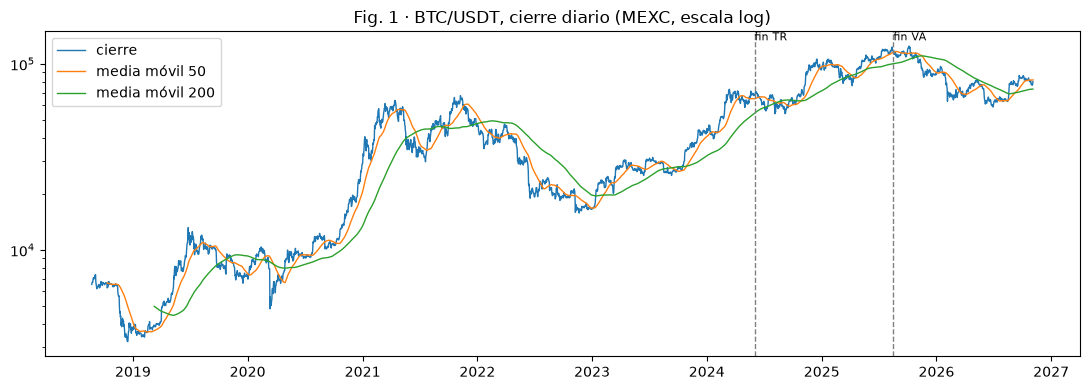

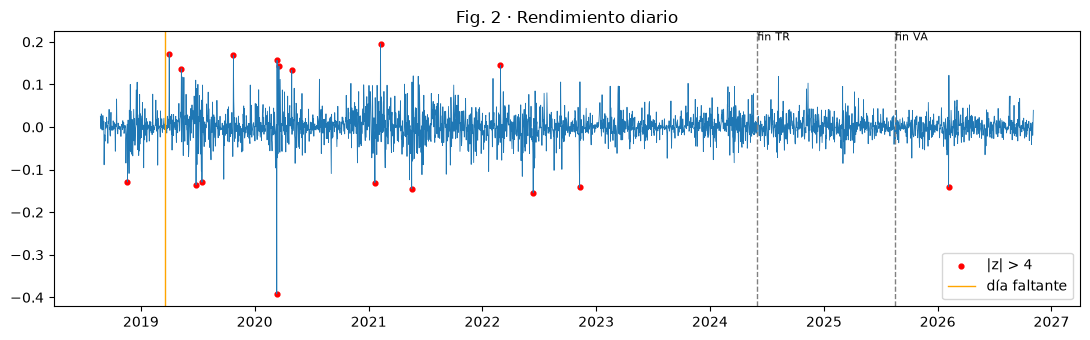

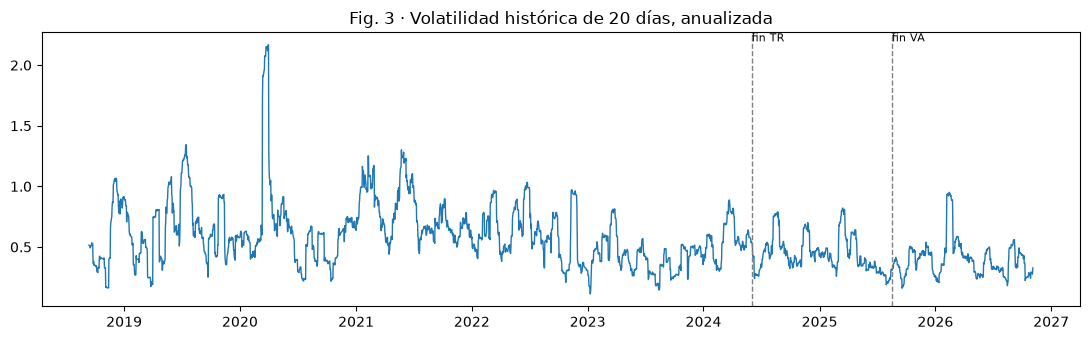

In [10]:
lim = [TR.fecha_objetivo.max(), VA.fecha_objetivo.max()]
def cortes(ax):
    for x, t in zip(lim, ["fin TR", "fin VA"]):
        ax.axvline(x, color="gray", ls="--", lw=1); ax.text(x, ax.get_ylim()[1], t, fontsize=8, va="top")

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df.index, df.close, lw=1, label="cierre"); ax.plot(df.index, df.close.rolling(50).mean(), lw=1, label="media móvil 50")
ax.plot(df.index, df.close.rolling(200).mean(), lw=1, label="media móvil 200"); ax.set_yscale("log"); cortes(ax)
ax.set_title("Fig. 1 · BTC/USDT, cierre diario (MEXC, escala log)"); ax.legend(); fig.tight_layout(); fig.savefig("figures/fig01_precio.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(r.index, r, lw=0.6); ax.scatter(extremos.index, extremos.rendimiento, color="red", s=12, label="|z| > 4")
for d in faltan: ax.axvline(pd.Timestamp(d), color="orange", lw=1, label="día faltante")
cortes(ax); ax.set_title("Fig. 2 · Rendimiento diario"); ax.legend(); fig.tight_layout(); fig.savefig("figures/fig02_rendimientos.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(vol20.index, vol20, lw=1); cortes(ax)
ax.set_title("Fig. 3 · Volatilidad histórica de 20 días, anualizada"); fig.tight_layout(); fig.savefig("figures/fig03_volatilidad.png", dpi=120); plt.show()

## 8. Estudio técnico descriptivo e hipótesis
Observación (fig. 1, 3 y 4): el precio pasa largos tramos por encima o por debajo de sus medias móviles, y la volatilidad cambia por régimen:
de 2018 a 2022 la volatilidad anualizada va de 0.64 a 0.81; de 2023 en adelante, de 0.42 a 0.53 (tabla de la sección 4.1). TR cubre los dos regímenes; VA y TE, solo el de menor volatilidad.

**Hipótesis técnica verificable (H1):** la distancia del cierre a su media móvil de 20 días, dₜ = Pₜ / SMA20ₜ − 1, aporta información para pronosticar yₜ.
**Cómo se prueba (Avance 5, §11):** modelo A = regresión con los 20 rezagos; modelo B = el mismo más dₜ (SMA calculada solo con cierres hasta *t*).
Se comparan MAE y RMSE en VA, en las mismas fechas. H1 se acepta solo si B baja el MAE de VA frente a A.

Abajo solo se **describe** la relación en TR. Una figura o una correlación no implica capacidad predictiva.

Correlación (solo TR) entre d_t y y_t: 0.0128  ·  n = 2067  ·  descriptivo, no prueba nada


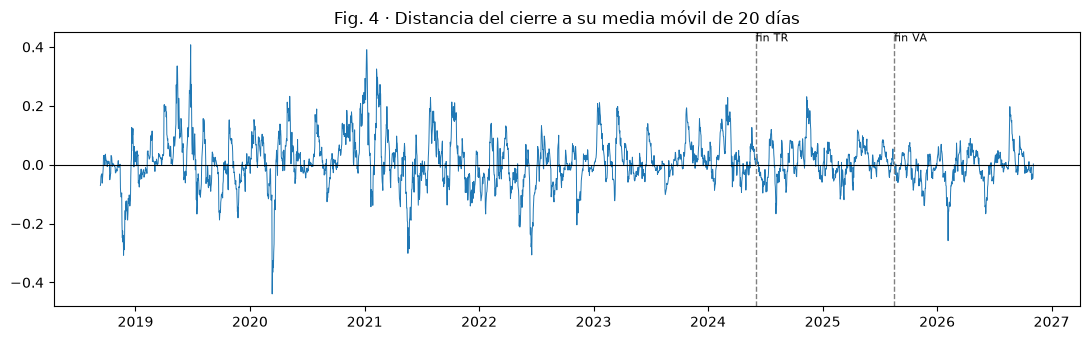

In [11]:
sma20 = df.close.rolling(20).mean()
dist = (df.close / sma20 - 1).rename("dist_sma20")
tr_d = pd.DataFrame({"d": dist.reindex(TR.fecha_emision).values, "y": TR.y.values}).dropna()
corr = tr_d.d.corr(tr_d.y)
print(f"Correlación (solo TR) entre d_t y y_t: {corr:.4f}  ·  n = {len(tr_d)}  ·  descriptivo, no prueba nada")
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(dist.index, dist, lw=0.7); ax.axhline(0, color="k", lw=0.8); cortes(ax)
ax.set_title("Fig. 4 · Distancia del cierre a su media móvil de 20 días"); fig.tight_layout(); fig.savefig("figures/fig04_distancia_sma20.png", dpi=120); plt.show()
json.dump({"hipotesis": "d_t = P_t/SMA20_t - 1 reduce el MAE de VA frente a solo rezagos", "corr_TR": round(float(corr), 4), "n_TR": len(tr_d)},
          open("outputs/hipotesis_tecnica.json", "w"), ensure_ascii=False, indent=1)

## 9. Manejo de errores: cuatro fallos provocados (protocolo §8)
Se provocan en **copias pequeñas** de los datos (los originales no se tocan): conjunto vacío, fecha duplicada, valor no válido y dimensiones incorrectas.
Cada fallo lanza una excepción específica con un mensaje que dice cómo resolverlo. Sin `except: pass`.

In [12]:
muestra = df.iloc[:40].copy()
bitacora = []
HUELLA_DF = pd.util.hash_pandas_object(df).sum()
CAUSA = {"conjunto vacío": ("filtro que no deja filas (copia recortada a 0)", "detener; revisar descarga o fechas; repetir con la copia completa"),
         "fecha duplicada": ("una vela repetida en la copia", "drop_duplicates(keep='first') y volver a validar"),
         "valor no válido": ("cierre negativo (−1) en la copia", "eliminar la fila; no imputar con datos futuros"),
         "dimensiones incorrectas": ("copia de 15 días: no alcanza para ventanas de 20", "detener antes de entrenar; usar más historia")}
casos = {
    "conjunto vacío": (lambda: validar(muestra.iloc[0:0]), lambda: validar(muestra)),
    "fecha duplicada": (lambda: validar(pd.concat([muestra, muestra.iloc[[5]]]).sort_index()),
                        lambda: validar(pd.concat([muestra, muestra.iloc[[5]]]).sort_index().pipe(lambda x: x[~x.index.duplicated(keep="first")]))),
    "valor no válido": (lambda: validar(muestra.assign(close=muestra.close.where(muestra.index != muestra.index[7], -1.0))),
                        lambda: validar(muestra.drop(index=muestra.index[7]))),
    "dimensiones incorrectas": (lambda: ventanas(muestra.iloc[:15]), lambda: ventanas(muestra)),
}
for nombre, (provocar, corregir) in casos.items():
    try:
        provocar(); raise AssertionError(f"{nombre}: el fallo no se detectó")
    except ErrorDatos as e:
        mensaje = str(e)
    res = corregir()
    bitacora.append({"fecha": datetime.now(timezone.utc).strftime("%Y-%m-%d"), "etapa": "preparación (prueba controlada)", "error": nombre,
                     "causa": CAUSA[nombre][0], "mensaje": mensaje, "accion_correctiva": CAUSA[nombre][1],
                     "resultado_verificacion": f"recuperado con la corrección: {len(res)} filas o ventanas válidas"})
    print(f"[{nombre}] detenido → {mensaje}\n   corrección verificada: {len(res)} filas")
# Incidentes reales de la auditoría, en la misma bitácora
sin_cruce = bool(((datos.fecha_objetivo - datos.fecha_inicio_entrada).dt.days == VENTANA + 1).all())
REAL = {"3.": ("la vela del día de la descarga aún no cerraba", "eliminarla (regla 3)", "la última vela válida cerró antes de la descarga"),
        "5.": ("MEXC cambió el cierre de la vela diaria de 16:00 a 00:00 UTC", "usar solo desde 2018-08-23 (regla 5)", "todas las velas abren a las 00:00 UTC"),
        "6.": ("MEXC no publica la vela del " + ", ".join(faltan), "no rellenar; retirar ventanas que lo cruzan (regla 6)",
               f"ninguna ventana cruza el hueco: {sin_cruce}")}
for regla, filas_, det in aud[1:-1]:
    if filas_ and regla[:2] in REAL:
        causa, accion, verif = REAL[regla[:2]]
        bitacora.append({"fecha": FICHA["fecha_descarga_utc"][:10], "etapa": "preparación (datos reales)", "error": f"{regla} ({filas_})",
                         "causa": causa, "mensaje": det, "accion_correctiva": accion, "resultado_verificacion": verif})
pd.DataFrame(bitacora).to_csv("outputs/bitacora_errores.csv", index=False)
intactos = hashlib.sha256(open(RAW, "rb").read()).hexdigest() == HUELLA_RAW and pd.util.hash_pandas_object(df).sum() == HUELLA_DF
print("Originales intactos (huella SHA-256 del crudo y del DataFrame auditado):", intactos)
assert intactos and sin_cruce
pd.DataFrame(bitacora)[["etapa", "error", "resultado_verificacion"]]

[conjunto vacío] detenido → Conjunto vacío: revisa la descarga o el filtro de fechas antes de seguir.
   corrección verificada: 40 filas
[fecha duplicada] detenido → Fechas duplicadas ['2018-08-28']: aplica drop_duplicates(keep='first') y vuelve a validar.
   corrección verificada: 40 filas
[valor no válido] detenido → Precio no válido en ['2018-08-30']: elimina esas filas; no imputes con datos futuros.
   corrección verificada: 39 filas
[dimensiones incorrectas] detenido → Forma esperada (n ≥ 1, 20) y recibida (14,) rendimientos: detente antes de entrenar y pide más historia.
   corrección verificada: 20 filas
Originales intactos (huella SHA-256 del crudo y del DataFrame auditado): True


,etapa,error,resultado_verificacion
0,preparación (prueba controlada),conjunto vacío,recuperado con la corrección: 40 filas o venta...
1,preparación (prueba controlada),fecha duplicada,recuperado con la corrección: 40 filas o venta...
2,preparación (prueba controlada),valor no válido,recuperado con la corrección: 39 filas o venta...
3,preparación (prueba controlada),dimensiones incorrectas,recuperado con la corrección: 20 filas o venta...
4,preparación (datos reales),3. vela abierta eliminada (1),la última vela válida cerró antes de la descarga
5,preparación (datos reales),5. velas con horario 16:00 UTC (antes de 2018-...,todas las velas abren a las 00:00 UTC
6,preparación (datos reales),6. días faltantes (no se rellenan) (1),ninguna ventana cruza el hueco: True


## 10. Comprobación previa (antes de avanzar al capítulo 8)

In [13]:
chk = {
    "≥ 1,500 observaciones válidas": len(df) >= 1500,
    "índice único y ordenado": df.index.is_unique and df.index.is_monotonic_increasing,
    "TR < VA < TE por fecha objetivo": TR.fecha_objetivo.max() < VA.fecha_objetivo.min() and VA.fecha_objetivo.max() < TE.fecha_objetivo.min(),
    "proporciones 70/15/15 (±1 ejemplo)": abs(len(TR) - 0.70 * n) <= 1 and abs(len(VA) - 0.15 * n) <= 1,
    "escalador ajustado solo con TR": esc.n_samples_seen_ == len(TR),
    "TE sin usar en métricas": set(metricas.conjunto) == {"TR", "VA"},
    "datos y predicciones finitos": np.isfinite(datos[CAR + ["y"]].values).all() and all(np.isfinite(v).all() for p in pred.values() for v in p.values()),
    "objetivo alineado con el precio": bool(np.allclose(datos.y, df.close.reindex(datos.fecha_objetivo).values / df.close.reindex(datos.fecha_emision).values - 1)),
    "4 fallos provocados y recuperados": sum(b["etapa"].endswith("controlada)") for b in bitacora) == 4,
    "originales intactos tras las pruebas": intactos,
    "4 figuras guardadas": all(os.path.exists(f"figures/{f}") for f in ["fig01_precio.png", "fig02_rendimientos.png", "fig03_volatilidad.png", "fig04_distancia_sma20.png"]),
}
for k, v in chk.items():
    print(("OK   " if v else "FALLA ") + k)
json.dump({"filas_validas": len(df), "ejemplos": n, "particiones": particiones.astype(str).to_dict("records"),
           "metricas": metricas.round(6).to_dict("records"), "comprobacion": {k: bool(v) for k, v in chk.items()}, "versiones": VERSIONES},
          open("outputs/resumen.json", "w"), ensure_ascii=False, indent=1, default=str)
assert all(chk.values())

OK   ≥ 1,500 observaciones válidas
OK   índice único y ordenado
OK   TR < VA < TE por fecha objetivo
OK   proporciones 70/15/15 (±1 ejemplo)
OK   escalador ajustado solo con TR
OK   TE sin usar en métricas
OK   datos y predicciones finitos
OK   objetivo alineado con el precio
OK   4 fallos provocados y recuperados
OK   originales intactos tras las pruebas
OK   4 figuras guardadas


## 11. Reflexión del capítulo 7 y seguimiento
**Qué hicimos:** descargamos BTC/USDT diario de MEXC, lo auditamos con reglas explícitas, construimos el objetivo de un día y 20 rezagos, separamos TR–VA–TE por fecha del objetivo y medimos dos referencias sin tocar TE.

**¿Qué tendría que mejorar el modelo profundo frente a pronosticar cero?** Bajar el MAE y el RMSE de **VA** por debajo de los del pronóstico cero *y* de la regresión lineal
(tabla de la sección 6), en las mismas fechas. Como el cero ya es casi imbatible en error, el aporte real del modelo profundo se tendrá que ver también en la
**señal** (acertar la dirección en los días de mayor movimiento) después de costos, que es lo que se prueba en los capítulos 9 y 10.

**Antes de avanzar:** la alineación temporal se comprobó en 5.1 y en la comprobación previa; el escalador se ajustó solo con TR (`n_samples_seen_` = tamaño de TR).

**Qué sigue (Avance 2, capítulo 8):** entrenar en Colab con T4 (guardar `nvidia-smi`, dispositivo, versiones, semilla y checkpoints) una red (LSTM o MLP) con las mismas ventanas y compararla con estas dos referencias en VA.